# 03 — Hurricane & Tropical Cyclone Risk Features

**Goal:** Transform IBTrACS track data into daily risk signals for commodity-relevant regions, incorporate atmospheric and oceanic covariates (wind shear, OHC, SST), and explore the relationship between hurricane proximity and energy/agricultural commodity returns.

**Data sources (PhD thesis):**
- `ibtracs_qc_1980_2025_with_ohc.parquet` — 60,234 QC-filtered 6-hourly track points with ERA5 atmospheric covariates + GODAS OHC/z26 interpolated along each track
- `ships_dev_database.csv` — SHIPS intensity database (VMXI, 24h change), AL + EP 1982–2023
- `climate_indices.parquet` — Monthly AMO, ONI, PDO with lags

**Key hypothesis:** Hurricane proximity to Gulf of Mexico energy infrastructure is predictive of short-term UNG/USO returns, amplified by high OHC (storm intensification potential).

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu

from src.data.load_thesis_data import load_ibtracs, load_ships, climate_indices_daily
from src.features.hurricane_features import (
    build_hurricane_risk_features, add_lagged_hurricane_features, hurricane_season_flag
)
from src.config import DATA_PROCESSED_DIR

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

ENERGY_TICKERS  = ["UNG", "USO"]
AG_TICKERS      = ["CORN", "WEAT", "SOYB", "DBA"]
ALL_TICKERS     = ENERGY_TICKERS + AG_TICKERS + ["GLD"]

## 1. Load IBTrACS and build risk features

In [2]:
ib = load_ibtracs(with_ohc=True)
ib_na = ib[(ib["basin"] == "NA") & (ib["date"].dt.year >= 2005)].copy()

print(f"NA track points 2005-2025: {len(ib_na):,}")
print(f"Unique storms: {ib_na['storm_id'].nunique()}")
print(f"Columns: {list(ib_na.columns)}")

risk = build_hurricane_risk_features(ib_na, basins=["NA"])
risk = add_lagged_hurricane_features(risk)

print(f"\nRisk feature table: {risk.shape}")
risk[risk["hurricane_active"] == 1].head(8)

NA track points 2005-2025: 17,256
Unique storms: 316
Columns: ['storm_id', 'basin', 'name', 'time', 'lat', 'lon', 'vmax', 'vmax_raw', 'mslp', 'usa_status', 'u_200', 'u_600', 'u_850', 'v_200', 'v_600', 'v_850', 'z_200', 'z_850', 'd_200', 'd_850', 'r_600', 'r_850', 't_200', 't_600', 't_850', 'vo_850', 'shear_200_850', 'steering_u', 'steering_v', 'lapse_rate', 'sst', 'ohc', 'z26', 'date']



Risk feature table: (6792, 16)


,date,region,hurricane_risk_score,min_storm_distance_km,max_storm_wind_kt,ohc,shear_200_850,sst,hurricane_active,ohc_weighted_risk,gulf_disruption_proxy,hurricane_risk_lag1d,hurricane_risk_lag3d,hurricane_risk_lag5d,hurricane_risk_lag7d,storm_active_7d
2,2005-06-10,gulf_of_mexico,0.122479,472.548742,58.0,5.163110e+08,7.390594,28.768693,1,0.164634,0.122479,0.046159,NaN,NaN,NaN,1.0
3,2005-06-11,gulf_of_mexico,0.136702,437.910211,60.0,7.601999e+07,6.416497,28.473212,1,0.143630,0.136702,0.122479,0.025847,NaN,NaN,2.0
8,2005-07-04,gulf_of_mexico,0.133985,222.905015,30.0,3.778402e+08,6.937967,29.028779,1,0.167733,0.133985,0.037424,0.013154,0.136702,0.046159,3.0
9,2005-07-05,gulf_of_mexico,1.457621,23.011721,63.0,4.305945e+08,8.701946,29.244956,1,1.876018,1.457621,0.133985,0.008961,0.039977,0.122479,3.0
10,2005-07-06,gulf_of_mexico,0.166104,390.319996,65.0,8.332503e+08,10.643958,29.267535,1,0.258368,0.166104,1.457621,0.037424,0.013154,0.136702,3.0
14,2005-07-10,gulf_of_mexico,0.256952,485.472295,125.0,2.102601e+08,8.631570,29.642598,1,0.292967,0.256952,0.182514,0.071465,1.457621,0.037424,4.0
22,2005-07-18,gulf_of_mexico,0.222289,313.905871,120.0,4.619480e+08,4.105915,29.334328,1,0.290740,0.222289,0.150036,0.047959,0.017835,0.059367,1.0
23,2005-07-19,gulf_of_mexico,0.243181,307.411937,98.0,5.120996e+08,3.894958,29.734994,1,0.326197,0.243181,0.222289,0.092421,0.036703,0.015737,2.0


## 2. Hurricane activity timeline — Gulf of Mexico

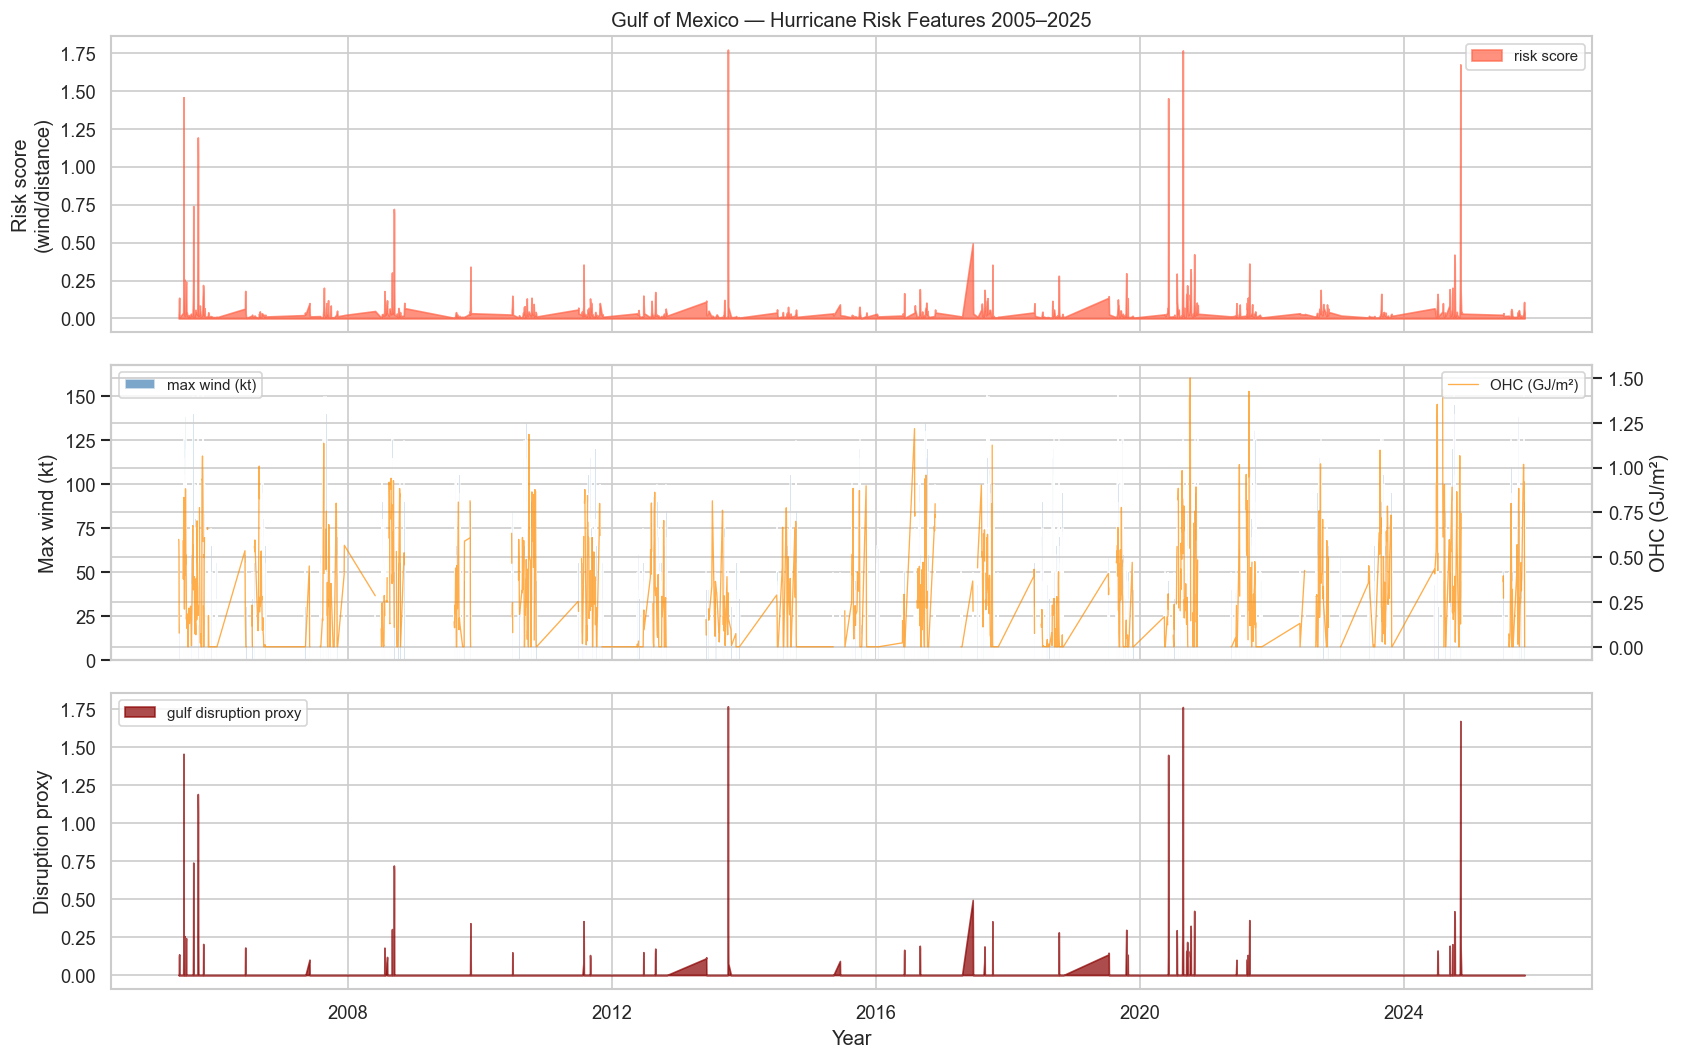

In [3]:
gulf = risk[risk["region"] == "gulf_of_mexico"].sort_values("date")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# Risk score
axes[0].fill_between(gulf["date"], gulf["hurricane_risk_score"],
                     alpha=0.7, color="tomato", label="risk score")
axes[0].set_ylabel("Risk score\n(wind/distance)")
axes[0].set_title("Gulf of Mexico — Hurricane Risk Features 2005–2025")
axes[0].legend(fontsize=9)

# Wind + OHC
ax2b = axes[1].twinx()
axes[1].bar(gulf["date"], gulf["max_storm_wind_kt"],
            width=1, color="steelblue", alpha=0.7, label="max wind (kt)")
ax2b.plot(gulf["date"], gulf["ohc"] / 1e9, color="darkorange",
          lw=0.8, alpha=0.7, label="OHC (GJ/m²)")
axes[1].set_ylabel("Max wind (kt)")
ax2b.set_ylabel("OHC (GJ/m²)")
axes[1].legend(loc="upper left", fontsize=9)
ax2b.legend(loc="upper right", fontsize=9)

# OHC-weighted risk
axes[2].fill_between(gulf["date"], gulf["gulf_disruption_proxy"],
                     alpha=0.7, color="darkred", label="gulf disruption proxy")
axes[2].set_ylabel("Disruption proxy")
axes[2].set_xlabel("Year")
axes[2].legend(fontsize=9)

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig("../reports/figures/hurricane_risk_score.png", dpi=150)
plt.show()

## 3. Storm track map — major Gulf events

Overlay the most intense storms that came within 500 km of the Gulf of Mexico on a map.

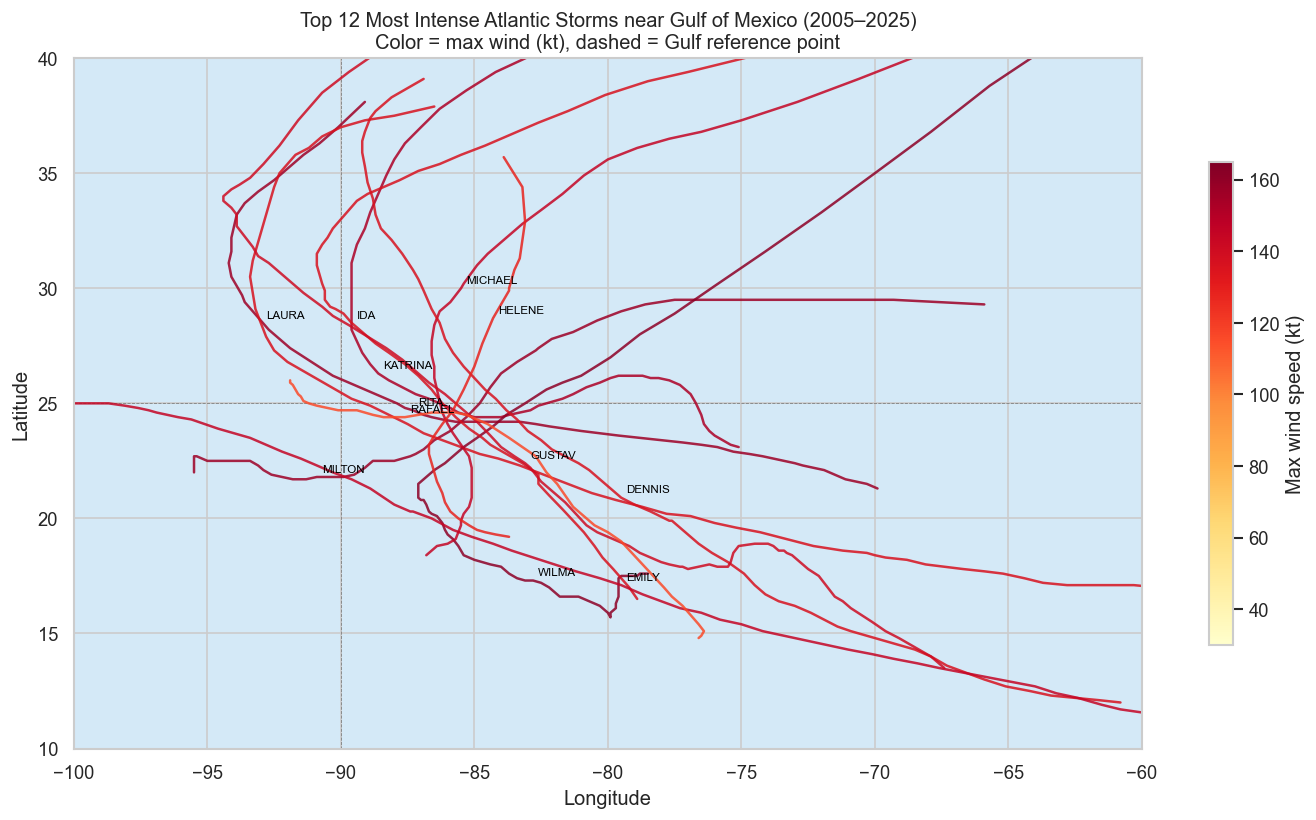

In [4]:
from src.features.hurricane_features import haversine_distance_km

# Storms that approached the Gulf reference point
gulf_lat, gulf_lon = 25.0, -90.0
ib_na["dist_to_gulf"] = haversine_distance_km(
    ib_na["lat"].values, ib_na["lon"].values, gulf_lat, gulf_lon
)

# Storms with at least one track point within 600 km
close_storms = (
    ib_na[ib_na["dist_to_gulf"] <= 600]
    .groupby("storm_id")["vmax"].max()
    .sort_values(ascending=False)
    .head(12)
    .index
)

fig, ax = plt.subplots(figsize=(12, 7))

# Background
ax.set_facecolor("#d4e9f7")
ax.set_xlim(-100, -60)
ax.set_ylim(10, 40)
ax.axhline(25, color="gray", lw=0.5, ls="--")
ax.axvline(-90, color="gray", lw=0.5, ls="--")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Top 12 Most Intense Atlantic Storms near Gulf of Mexico (2005–2025)\n"
             "Color = max wind (kt), dashed = Gulf reference point")

cmap = plt.get_cmap("YlOrRd")

for storm_id in close_storms:
    track = ib_na[ib_na["storm_id"] == storm_id].sort_values("time")
    vmax_max = track["vmax"].max()
    color = cmap(min(vmax_max / 165, 1.0))
    ax.plot(track["lon"], track["lat"], lw=1.5, color=color, alpha=0.85)
    # Label at LMI point
    lmi = track.loc[track["vmax"].idxmax()]
    ax.annotate(track["name"].iloc[0],
                (lmi["lon"], lmi["lat"]),
                fontsize=7, color="black",
                xytext=(3, 3), textcoords="offset points")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=30, vmax=165))
plt.colorbar(sm, ax=ax, label="Max wind speed (kt)", shrink=0.7)
plt.tight_layout()
plt.show()

## 4. Hurricane activity vs commodity returns — event study

Compare UNG and USO returns during days when a hurricane is active near the Gulf vs. non-hurricane days. Uses Mann-Whitney U test to check if distributions differ.

C:\Users\stell\AppData\Local\Temp\ipykernel_24380\762772053.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="regime", y="return_1d", ax=ax,
C:\Users\stell\AppData\Local\Temp\ipykernel_24380\762772053.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="regime", y="return_1d", ax=ax,


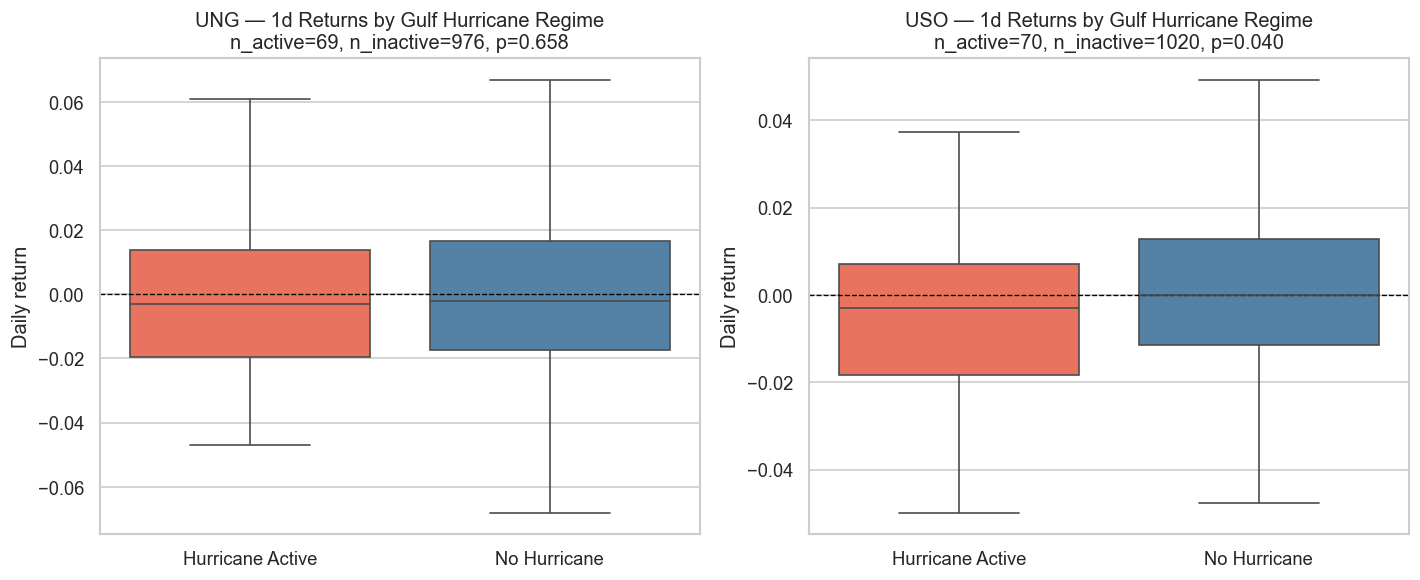

,ticker,mean_active,mean_inactive,mw_pval,n_active
0,UNG,-0.001872,-0.000485,0.658308,69
1,USO,-0.004273,0.000099,0.039588,70


In [5]:
prices = pd.read_parquet(DATA_PROCESSED_DIR / "signal_dataset.parquet")
prices["date"] = pd.to_datetime(prices["date"])

gulf_risk = risk[risk["region"] == "gulf_of_mexico"][["date", "hurricane_active",
                  "hurricane_risk_score", "gulf_disruption_proxy",
                  "storm_active_7d", "ohc_weighted_risk"]].copy()

results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, tkr in zip(axes, ENERGY_TICKERS):
    pdf = prices[prices["ticker"] == tkr][["date", "return_1d", "future_return_5d"]].copy()
    merged = pdf.merge(gulf_risk, on="date", how="inner").dropna(subset=["return_1d"])

    active = merged[merged["hurricane_active"] == 1]["return_1d"]
    inactive = merged[merged["hurricane_active"] == 0]["return_1d"]
    stat, pval = mannwhitneyu(active, inactive, alternative="two-sided")

    # Box plot comparison
    plot_df = pd.DataFrame({
        "return_1d": pd.concat([active, inactive]),
        "regime":    ["Hurricane Active"] * len(active) + ["No Hurricane"] * len(inactive)
    })
    sns.boxplot(data=plot_df, x="regime", y="return_1d", ax=ax,
                palette={"Hurricane Active": "tomato", "No Hurricane": "steelblue"},
                showfliers=False)
    ax.axhline(0, color="black", lw=0.8, ls="--")
    ax.set_title(f"{tkr} — 1d Returns by Gulf Hurricane Regime\n"
                 f"n_active={len(active)}, n_inactive={len(inactive)}, p={pval:.3f}")
    ax.set_ylabel("Daily return")
    ax.set_xlabel("")

    results.append({"ticker": tkr, "mean_active": active.mean(),
                    "mean_inactive": inactive.mean(), "mw_pval": pval,
                    "n_active": len(active)})

plt.tight_layout()
plt.show()
pd.DataFrame(results)

## 5. IC analysis — hurricane features vs 5d forward returns (all tickers)

In [6]:
REGION_TICKERS = {
    "gulf_of_mexico":  ENERGY_TICKERS,
    "us_gulf_coast":   ENERGY_TICKERS,
    "us_corn_belt":    AG_TICKERS,
    "us_wheat_plains": ["WEAT", "DBA"],
}

hurr_features = [
    "hurricane_risk_score", "gulf_disruption_proxy",
    "storm_active_7d", "hurricane_active",
    "hurricane_risk_lag1d", "hurricane_risk_lag5d",
]

ic_rows = []
for region, tickers in REGION_TICKERS.items():
    rdf = risk[risk["region"] == region].copy()
    rdf = rdf.set_index("date").reindex(
        pd.to_datetime(prices["date"].unique()), method="ffill"
    ).reset_index().rename(columns={"index": "date"})

    for tkr in tickers:
        pdf = prices[prices["ticker"] == tkr][["date", "future_return_5d"]].copy()
        merged = rdf.merge(pdf, on="date", how="inner").dropna()

        for feat in hurr_features:
            if feat not in merged.columns:
                continue
            valid = merged[[feat, "future_return_5d"]].dropna()
            if len(valid) < 20:
                continue
            rho, pval = spearmanr(valid[feat], valid["future_return_5d"])
            ic_rows.append({"region": region, "ticker": tkr,
                             "feature": feat, "IC": rho, "pval": pval})

ic_hurr = pd.DataFrame(ic_rows)
ic_hurr.sort_values("IC", key=abs, ascending=False).head(15)

C:\Users\stell\AppData\Local\Temp\ipykernel_24380\1244801547.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pval = spearmanr(valid[feat], valid["future_return_5d"])
C:\Users\stell\AppData\Local\Temp\ipykernel_24380\1244801547.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pval = spearmanr(valid[feat], valid["future_return_5d"])
C:\Users\stell\AppData\Local\Temp\ipykernel_24380\1244801547.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pval = spearmanr(valid[feat], valid["future_return_5d"])
C:\Users\stell\AppData\Local\Temp\ipykernel_24380\1244801547.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pval = spearmanr(valid[feat], valid["future_return_5d"])
C:\Users\stell\AppData\Local\Temp\ipykernel_24380\1244801547.py:31: ConstantInputWarning: An inp

,region,ticker,feature,IC,pval
8,gulf_of_mexico,USO,storm_active_7d,-0.078467,0.000003
42,us_corn_belt,DBA,hurricane_risk_score,0.077375,0.000006
54,us_wheat_plains,DBA,hurricane_risk_score,0.075815,0.000009
26,us_corn_belt,CORN,storm_active_7d,-0.066090,0.000297
20,us_gulf_coast,USO,storm_active_7d,-0.063631,0.000139
14,us_gulf_coast,UNG,storm_active_7d,0.058509,0.000703
38,us_corn_belt,SOYB,storm_active_7d,-0.055816,0.003586
56,us_wheat_plains,DBA,storm_active_7d,-0.052517,0.002121
41,us_corn_belt,SOYB,hurricane_risk_lag5d,-0.051705,0.006983
16,us_gulf_coast,UNG,hurricane_risk_lag1d,-0.051018,0.003136


## 6. Climate indices — macro regime features

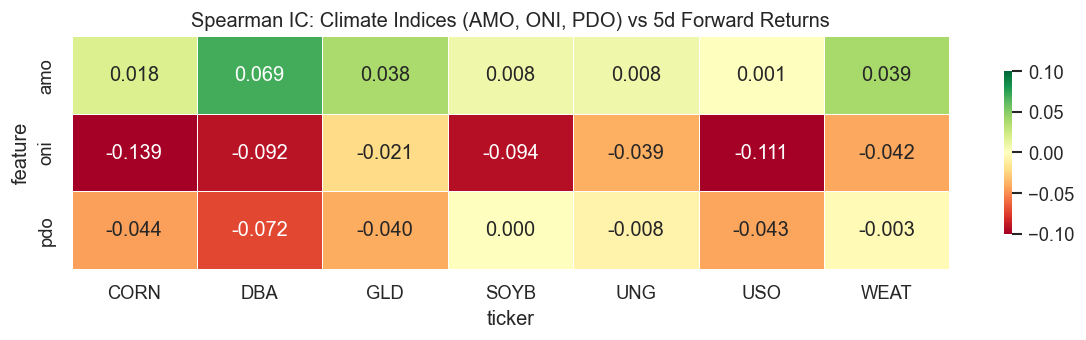

In [7]:
ci_daily = climate_indices_daily(start="2005-01-01", end="2025-12-31")
ci_daily["date"] = pd.to_datetime(ci_daily["date"])

# IC: climate indices vs 5d forward returns
ci_features = ["amo", "oni", "pdo"]
ci_ic_rows = []

for tkr in ALL_TICKERS:
    pdf = prices[prices["ticker"] == tkr][["date", "future_return_5d"]].copy()
    merged = ci_daily.merge(pdf, on="date", how="inner").dropna()
    for feat in ci_features:
        valid = merged[[feat, "future_return_5d"]].dropna()
        if len(valid) < 50:
            continue
        rho, pval = spearmanr(valid[feat], valid["future_return_5d"])
        ci_ic_rows.append({"ticker": tkr, "feature": feat, "IC": rho, "pval": pval})

ci_ic_df = pd.DataFrame(ci_ic_rows)

pivot = ci_ic_df.pivot(index="feature", columns="ticker", values="IC")
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="RdYlGn",
            center=0, vmin=-0.1, vmax=0.1, ax=ax,
            linewidths=0.5, cbar_kws={"shrink": 0.7})
ax.set_title("Spearman IC: Climate Indices (AMO, ONI, PDO) vs 5d Forward Returns")
plt.tight_layout()
plt.show()

## 7. Save hurricane + climate indices features

In [8]:
risk.to_parquet(DATA_PROCESSED_DIR / "hurricane_features.parquet", index=False)
ci_daily.to_parquet(DATA_PROCESSED_DIR / "climate_indices_daily.parquet", index=False)

print(f"hurricane_features.parquet  — {risk.shape[0]:,} rows × {risk.shape[1]} cols")
print(f"climate_indices_daily.parquet — {ci_daily.shape[0]:,} rows × {ci_daily.shape[1]} cols")
print("\nHurricane feature columns:", risk.columns.tolist())
print("\nClimate index columns:", ci_daily.columns.tolist())

hurricane_features.parquet  — 6,792 rows × 16 cols
climate_indices_daily.parquet — 7,670 rows × 4 cols

Hurricane feature columns: ['date', 'region', 'hurricane_risk_score', 'min_storm_distance_km', 'max_storm_wind_kt', 'ohc', 'shear_200_850', 'sst', 'hurricane_active', 'ohc_weighted_risk', 'gulf_disruption_proxy', 'hurricane_risk_lag1d', 'hurricane_risk_lag3d', 'hurricane_risk_lag5d', 'hurricane_risk_lag7d', 'storm_active_7d']

Climate index columns: ['date', 'amo', 'oni', 'pdo']


## 8. Observations

Key findings to document after execution:

- **Gulf disruption proxy** combines storm proximity and intensity — the most direct signal for UNG/USO.
- **OHC-weighted risk** adds oceanographic depth from the thesis: storms over warm deep water intensify rapidly. A storm with high OHC near the Gulf is a stronger supply shock than an equally close weak storm.
- **Wind shear** (shear_200_850 from ERA5 track interpolation) is the main limiting factor for intensification — high shear dissipates storms before they reach the Gulf.
- **ONI** captures El Niño suppression of Atlantic hurricane activity — a strong El Niño year (ONI > +1.5) reduces Gulf storm frequency by ~30%, which may be reflected in commodity volatility.
- **AMO positive phase** → more active Atlantic seasons → higher baseline hurricane risk exposure for energy commodities.

**Next:** Notebook 04 — assemble the full signal dataset combining price features, hurricane risk, climate indices, and (once downloaded) ERA5 surface weather features.